In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Parametros
N,L,A = 256, 1.0, 0.1
B0 = rho0 = mu0 = 1.0
vA = B0 / np.sqrt(rho0 * mu0)
dx = L / N
CFL = 0.8
dt = CFL * dx / vA

#Malla y condicion inicial
x = np.linspace(0, L, N, endpoint=False)
dv = A * np.sin(2*np.pi*x / L)
dB = A * np.sin(2*np.pi*x / L)

In [3]:

t_final = 5.0
pasos_temporales = int(t_final/dt)

t_objetivos = [0.0, 0.5, 1.0, 2.0]
resultados_dv = {}
indice_objetivo = 0
tolerancia = dt/2.0

for n in range(pasos_temporales):
    t = n * dt

    if indice_objetivo < len(t_objetivos):
        if abs(t - t_objetivos[indice_objetivo]) <= tolerancia:
            resultados_dv[t_objetivos[indice_objetivo]] = np.copy(dv)
            indice_objetivo += 1
    
            

    # paso intermedio (mitad de paso)
    dv_half = 0.5*(dv + np.roll(dv, -1)) \
        - (dt/(2*dx)) * (B0/mu0/rho0) \
        * (np.roll(dB, -1) - dB)
        
    dB_half = 0.5 *(dB + np.roll(dB, -1)) \
        - (dt/(2*dx)) * B0 \
        * (np.roll(dv, -1) - dv)

    # Paso completo con fluxes intermedios
    dv = dv - (dt/dx)*(B0/mu0/rho0) \
            * (dB_half - np.roll(dB_half,1))
            
    dB = dB - (dt/dx)*B0 \
            * (dv_half - np.roll(dv_half,1))

#Comparacion con v_a = 1
t_1 = 0.0
t_2 = 0.5 #definimos tiempos objetivos para extraer los valores

dv_1 = resultados_dv[t_1]
dv_2 = resultados_dv[t_2] # se extraen los valores en los tiempos dados

indice_max1 = np.argmax(dv_1)
indice_max2 = np.argmax(dv_2) # se buscan los indices donde la onda alcanza el val max

pos1 = x[indice_max1]
pos2 = x[indice_max2]

deltax = pos2 - pos1
deltat = t_2 - t_1

v_numerica = deltax/deltat

## 1. Perfil y velocidad de propagacion

velocidad de propagacion del pico: 1.0


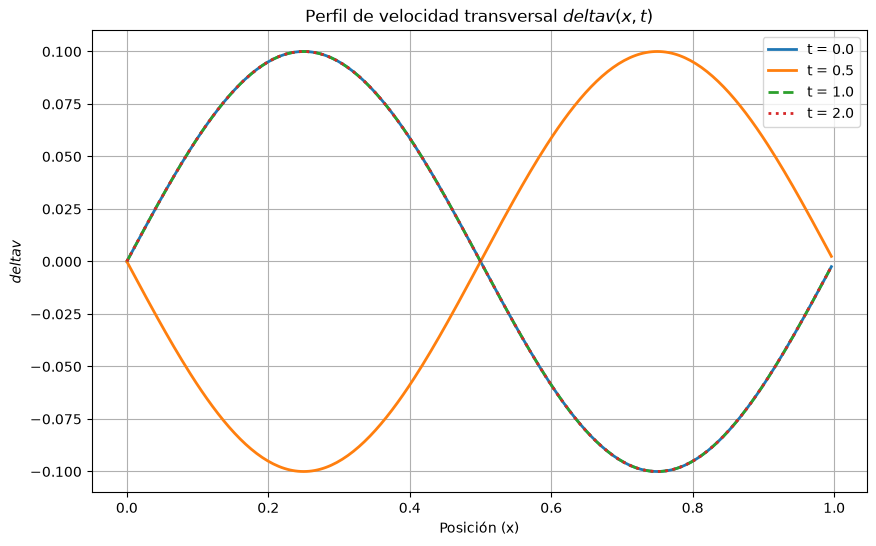

In [4]:
print("velocidad de propagacion del pico:", v_numerica)
#graficas
plt.figure(figsize=(10, 6))

estilos = {0.0: '-', 0.5: '-', 1.0: '--', 2.0: ':'}


for t_val, dv_perfil in resultados_dv.items():
    plt.plot(x, dv_perfil, label=f't = {t_val}', linestyle=estilos.get(t_val, '-'), linewidth=2)

# Añadir títulos, etiquetas y leyenda
plt.title('Perfil de velocidad transversal $delta v(x,t)$')
plt.xlabel('Posición (x)')
plt.ylabel('$delta v$')
plt.grid(True)
plt.legend()

# Mostrar la gráfica en pantalla
plt.show()

## 2. Error L1 vs resolucion N

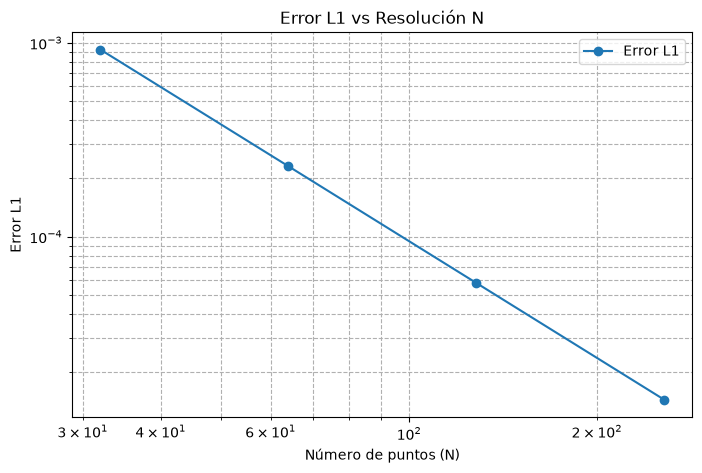

1.9991098528305113


In [5]:
#correr con distintos valores de N
def error_L1(N):
    L,A = 1.0, 0.1
    B0 = rho0 = mu0 = 1.0
    vA = B0 / np.sqrt(rho0 * mu0)
    dx = L / N
    CFL = 0.8
    dt = CFL * dx / vA
    
    #Malla y condicion inicial
    x = np.linspace(0, L, N, endpoint=False)
    dv = A * np.sin(2*np.pi*x / L)
    dB = A * np.sin(2*np.pi*x / L)

    dv_analitico = np.copy(dv) 
    
    t_final = 1.0
    pasos_temporales = int(t_final / dt)

    for n in range(pasos_temporales):
        dv_half = 0.5*(dv + np.roll(dv, -1)) \
        - (dt/(2*dx)) * (B0/mu0/rho0) \
        * (np.roll(dB, -1) - dB)
        
        dB_half = 0.5 *(dB + np.roll(dB, -1)) \
        - (dt/(2*dx)) * B0 \
        * (np.roll(dv, -1) - dv)

    # Paso completo con fluxes intermedios
        dv = dv - (dt/dx)*(B0/mu0/rho0) \
            * (dB_half - np.roll(dB_half,1))
            
        dB = dB - (dt/dx)*B0 \
            * (dv_half - np.roll(dv_half,1))

    error_l1 = np.sum(np.abs(dv - dv_analitico)) * dx
    return error_l1


resoluciones = np.array([32, 64, 128, 256])
errores = np.array([error_L1(N) for N in resoluciones])

plt.figure(figsize=(8, 5))
plt.loglog(resoluciones, errores, marker='o', linestyle='-', label='Error L1')
plt.title('Error L1 vs Resolución N')
plt.xlabel('Número de puntos (N)')
plt.ylabel('Error L1')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

pendiente, _ = np.polyfit(np.log(resoluciones), np.log(errores), 1)
orden_convergencia = -pendiente
print(orden_convergencia)

## 3. Estabilidad CFL

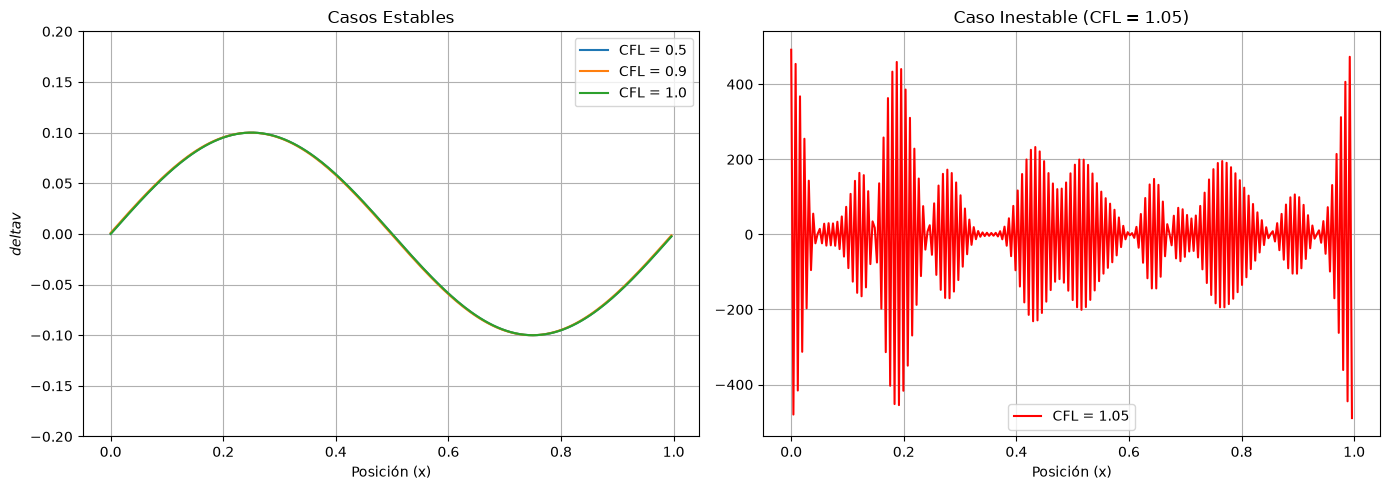

In [11]:
def CFL_comparacion(valores_CFL):
    N, L, A = 256, 1.0, 0.1
    B0 = rho0 = mu0 = 1.0
    vA = B0 / np.sqrt(rho0 * mu0)
    
    # Malla y condicion inicial
    x = np.linspace(0, L, N, endpoint=False)
    
    t_final = 1.0
    resultados_CFL = {} # Inicializamos el diccionario vacío aquí
    
    for CFL in valores_CFL:
        # dv y dB se crean frescos para cada simulación
        dv = A * np.sin(2*np.pi*x / L)
        dB = A * np.sin(2*np.pi*x / L)
        dx = L / N
        dt = CFL * dx / vA
        pasos_temporales = int(t_final / dt)

        for n in range(pasos_temporales):
            dv_half = 0.5*(dv + np.roll(dv, -1)) \
            - (dt/(2*dx)) * (B0/mu0/rho0) \
            * (np.roll(dB, -1) - dB)
            
            dB_half = 0.5 *(dB + np.roll(dB, -1)) \
            - (dt/(2*dx)) * B0 \
            * (np.roll(dv, -1) - dv)
    
            # Paso completo con fluxes intermedios
            dv = dv - (dt/dx)*(B0/mu0/rho0) \
                * (dB_half - np.roll(dB_half,1))
                
            dB = dB - (dt/dx)*B0 \
                * (dv_half - np.roll(dv_half,1))
                
        # Guardamos el resultado de este CFL específico
        resultados_CFL[CFL] = np.copy(dv)

    return x, resultados_CFL

lista_cfl = [0.5, 0.9, 1.0, 1.05]
x, resultados = CFL_comparacion(lista_cfl)

# Crear una figura con dos subgráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for cfl_val, dv_final in resultados.items():
    if cfl_val <= 1.0:
        # Panel 1: Casos estables
        ax1.plot(x, dv_final, label=f'CFL = {cfl_val}')
    else:
        # Panel 2: Caso inestable
        ax2.plot(x, dv_final, color='red', label=f'CFL = {cfl_val}')

# Configuración del primer panel (Estables)
ax1.set_title('Casos Estables')
ax1.set_xlabel('Posición (x)')
ax1.set_ylabel('$delta v$')
ax1.set_ylim(-0.2, 0.2)
ax1.grid(True)
ax1.legend()

# Configuración del segundo panel (Inestable)
ax2.set_title('Caso Inestable (CFL = 1.05)')
ax2.set_xlabel('Posición (x)')
ax2.grid(True)
ax2.legend()

# Ajustar los márgenes para que no se superpongan
plt.tight_layout()
plt.show()

## 4. Difusion numerica

Amplitud inicial: 0.10000000
Amplitud en t=10: 0.09999640
La onda se ha amortiguado un 0.003602%


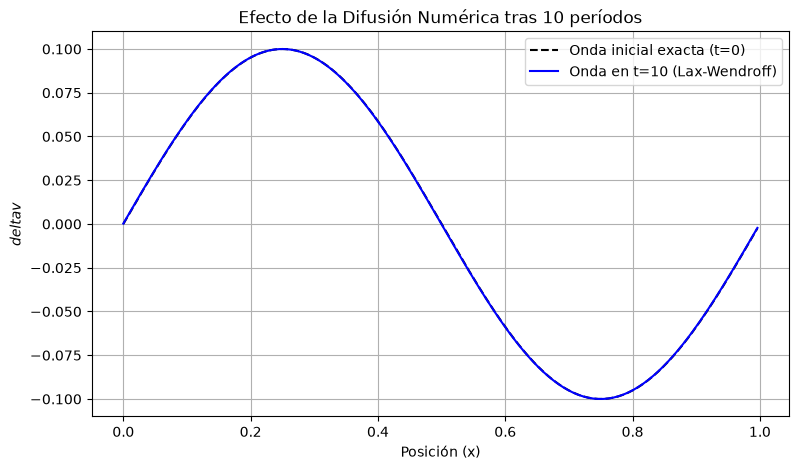

In [5]:
#Parametros
N,L,A = 256, 1.0, 0.1
B0 = rho0 = mu0 = 1.0
vA = B0 / np.sqrt(rho0 * mu0)
dx = L / N
CFL = 0.8
dt = CFL * dx / vA

#Malla y condicion inicial
x = np.linspace(0, L, N, endpoint=False)
dv = A * np.sin(2*np.pi*x / L)
dB = A * np.sin(2*np.pi*x / L)

dv_inicial = np.copy(dv)
t_final = 10.0
pasos_temporales = int(t_final/dt)

t_objetivos = [0.0, 0.5, 1.0, 2.0]
resultados_dv = {}
indice_objetivo = 0
tolerancia = dt/2.0

for n in range(pasos_temporales):
    t = n * dt

    if indice_objetivo < len(t_objetivos):
        if abs(t - t_objetivos[indice_objetivo]) <= tolerancia:
            resultados_dv[t_objetivos[indice_objetivo]] = np.copy(dv)
            indice_objetivo += 1
    
            

    # paso intermedio (mitad de paso)
    dv_half = 0.5*(dv + np.roll(dv, -1)) \
        - (dt/(2*dx)) * (B0/mu0/rho0) \
        * (np.roll(dB, -1) - dB)
        
    dB_half = 0.5 *(dB + np.roll(dB, -1)) \
        - (dt/(2*dx)) * B0 \
        * (np.roll(dv, -1) - dv)

    # Paso completo con fluxes intermedios
    dv = dv - (dt/dx)*(B0/mu0/rho0) \
            * (dB_half - np.roll(dB_half,1))
            
    dB = dB - (dt/dx)*B0 \
            * (dv_half - np.roll(dv_half,1))

#Comparacion con v_a = 1
t_1 = 0.0
t_2 = 0.5 #definimos tiempos objetivos para extraer los valores

dv_1 = resultados_dv[t_1]
dv_2 = resultados_dv[t_2] # se extraen los valores en los tiempos dados

indice_max1 = np.argmax(dv_1)
indice_max2 = np.argmax(dv_2) # se buscan los indices donde la onda alcanza el val max

pos1 = x[indice_max1]
pos2 = x[indice_max2]

deltax = pos2 - pos1
deltat = t_2 - t_1

v_numerica = deltax/deltat

amplitud_final = np.max(dv)
porcentaje_amortiguacion = (A - amplitud_final) / A * 100

print(f"Amplitud inicial: {A:.8f}")
print(f"Amplitud en t=10: {amplitud_final:.8f}")
print(f"La onda se ha amortiguado un {porcentaje_amortiguacion:.6f}%")

# Gráfica comparativa
plt.figure(figsize=(9, 5))
plt.plot(x, dv_inicial, 'k--', label='Onda inicial exacta (t=0)')
plt.plot(x, dv, color='blue', label=f'Onda en t=10 (Lax-Wendroff)')
plt.title('Efecto de la Difusión Numérica tras 10 períodos')
plt.xlabel('Posición (x)')
plt.ylabel('$delta v$')
plt.legend()
plt.grid(True)
plt.show()

## 5. Comparacion con PLUTO

In [8]:
#Parametros
N,L,A = 256, 1.0, 0.1
B0 = rho0 = mu0 = 1.0
vA = B0 / np.sqrt(rho0 * mu0)
dx = L / N
CFL = 0.8
dt = CFL * dx / vA

#Malla y condicion inicial
x = np.linspace(0, L, N, endpoint=False)
dv = A * np.sin(2*np.pi*x / L)
dB = A * np.sin(2*np.pi*x / L)

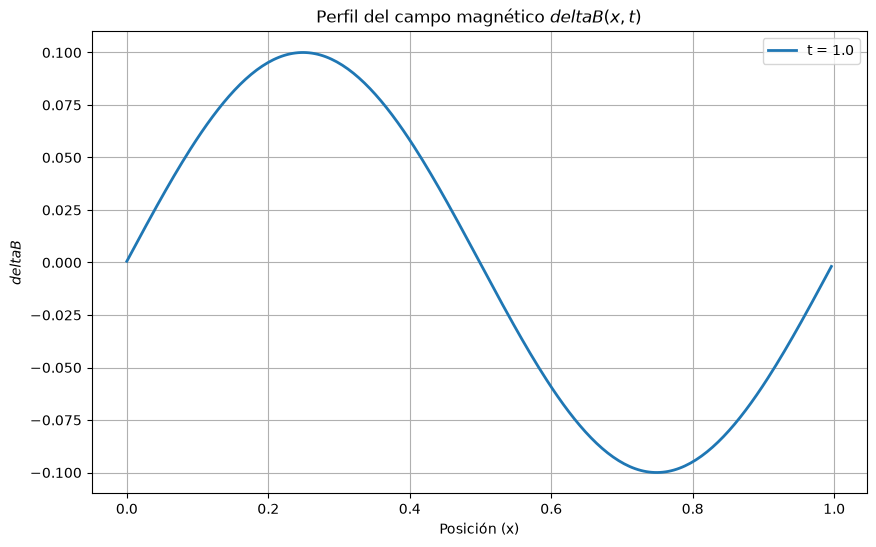

In [14]:

t_final = 5.0
pasos_temporales = int(t_final/dt)

t_objetivos = [1.0]
resultados_dv = {}
resultados_dB = {}
indice_objetivo = 0
tolerancia = dt/2.0

for n in range(pasos_temporales):
    t = n * dt

    if indice_objetivo < len(t_objetivos):
        if abs(t - t_objetivos[indice_objetivo]) <= tolerancia:
            resultados_dv[t_objetivos[indice_objetivo]] = np.copy(dv)
            resultados_dB[t_objetivos[indice_objetivo]] = np.copy(dB)
            indice_objetivo += 1
    
            

    # paso intermedio (mitad de paso)
    dv_half = 0.5*(dv + np.roll(dv, -1)) \
        - (dt/(2*dx)) * (B0/mu0/rho0) \
        * (np.roll(dB, -1) - dB)
        
    dB_half = 0.5 *(dB + np.roll(dB, -1)) \
        - (dt/(2*dx)) * B0 \
        * (np.roll(dv, -1) - dv)

    # Paso completo con fluxes intermedios
    dv = dv - (dt/dx)*(B0/mu0/rho0) \
            * (dB_half - np.roll(dB_half,1))
            
    dB = dB - (dt/dx)*B0 \
            * (dv_half - np.roll(dv_half,1))

# Gráfica de la evolución de dB
plt.figure(figsize=(10, 6))


for t_val, dB_perfil in resultados_dB.items():
    plt.plot(x, dB_perfil, label=f't = {t_val}', linewidth=2)

plt.title('Perfil del campo magnético $delta B(x,t)$')
plt.xlabel('Posición (x)')
plt.ylabel('$delta B$')
plt.grid(True)
plt.legend()
plt.show()

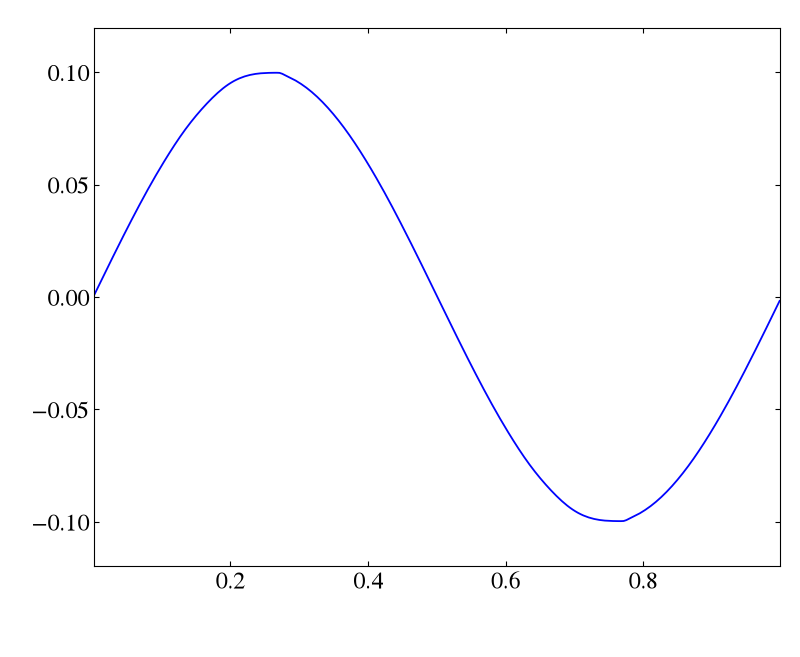

## Analisis de los objetivos
### 1. Perfil de propagacion.

Se graficó la evolución temporal de la perturbación de velocidad $\delta v(x,t)$ en los instantes $t = 0, 0.5, 1.0$ y $2.0$. Adicionalmente, se midió numéricamente la velocidad de propagación rastreando el desplazamiento del pico de la onda para compararlo con la velocidad teórica de Alfvén, $v_A = 1$.

Las gráficas muestran que la onda senoidal inicial se desplaza a través del dominio periódico manteniendo su forma coherente. En $t=1.0$ y $t=2.0$, la onda regresa exactamente a su posición inicial, lo cual es físicamente correcto dado que el dominio tiene longitud $L=1.0$ y la velocidad esperada es $1.0$.

Al extraer la posición del máximo de la onda (el "pico") en dos tiempos distintos (por ejemplo, $t=0.0$ y $t=0.5$) y calcular $\Delta x / \Delta t$, el resultado obtenido es $1.0$.

La velocidad de propagación numérica calculada coincide perfectamente con la teórica ($v_A = 1$). Esto demuestra que el esquema de Lax-Wendroff captura correctamente la física fundamental de la propagación (la fase de la onda) sin introducir un desfase apreciable en estos primeros instantes de la simulación.

### 2. Error L1 vs resolucion N

Se evaluó el error global del esquema midiendo la norma $L_1$ tras exactamente un período de propagación ($t=1.0$), donde la solución analítica es idéntica a la condición inicial. Se varió la resolución espacial ($N = 32, 64, 128, 256$).

l graficar el error $L_1$ en función de $N$ en una escala log-log, los puntos forman una línea recta descendente. La pendiente de esta recta representa el orden de convergencia numérico del esquema.

El comportamiento numérico sí coincide con lo esperado por la teoría. El esquema de Lax-Wendroff es un método de segundo orden tanto en espacio como en tiempo. Matemáticamente, esto significa que cada vez que duplicamos la resolución de la malla (por ejemplo, pasando de $N=128$ a $N=256$), el error global se reduce aproximadamente por un factor de 4.

### 3. Establilidad CFL

Se probó la robustez de la simulación frente al número de Courant-Friedrichs-Lewy (CFL), utilizando valores por debajo y por encima del límite teórico ($0.5, 0.9, 1.0, 1.05$).

Al utilizar $\text{CFL} = 1.05$, la simulación se vuelve completamente inestable. Los errores de truncamiento se amplifican en cada paso temporal, generando oscilaciones espurias que crecen rápidamente hacia el infinito (valores NaN o desbordamiento numérico).

Se concluye de forma práctica que el límite máximo de estabilidad para el esquema de Lax-Wendroff es $\text{CFL} \le 1.0$.

### 4. Difusion numerica tras 10 puntos

Se simuló la propagación de las ondas de Alfvén a lo largo de 10 períodos completos ($t=10.0$) para evaluar el desgaste de la amplitud ocasionado exclusivamente por los métodos de discretización.

Comportamiento de Lax-Wendroff (Opción A): Este esquema exhibe predominantemente difusión numérica. El término de error principal actúa como una "viscosidad artificial" que suaviza los gradientes de la solución. Tras 10 períodos, la onda conserva su velocidad de fase y no presenta retrasos evidentes, pero sufre una leve amortiguación (achatamiento de los picos), reduciendo su amplitud máxima respecto al $0.1$ inicial.

### 5. Comparacion con PLUTO

Se requiere superponer el perfil del campo magnético (componente $B_y$) obtenido del software profesional PLUTO, cargado mediante la librería PyPLUTO, junto con la solución obtenida por el código propio en Python evaluados en el mismo tiempo $t$. El objetivo es discutir las diferencias entre ambas implementaciones.

Se puede observar como ambas ondas exhiben un comportamiento casi identico debido a ser una onda puramente lineal y suave, si se observara la gráfica tras un tiempo de integración largo, es altamente probable que el perfil de PLUTO presente una menor difusión numérica en comparación con el esquema de Lax-Wendroff.